Test #   | Zeta     | Damping c (Ns/m) | Overshoot (%)  
-------------------------------------------------------
Take 1   | 0.4071   | 24.8389         | 24.7%
Take 2   | 0.3944   | 24.0631         | 26.0%
Take 3   | 0.3921   | 23.9247         | 26.2%
Take 4   | 0.3904   | 23.8183         | 26.4%
Take 5   | 0.4372   | 26.6741         | 21.7%
Take 6   | 0.4243   | 25.8867         | 22.9%
Take 7   | 0.4291   | 26.1790         | 22.5%
Take 8   | 0.3541   | 21.6018         | 30.4%
Take 9   | 0.3771   | 23.0079         | 27.8%
Take 10  | 0.4051   | 24.7155         | 24.9%
-------------------------------------------------------
AVERAGE  | 0.4011   | 24.4710         | -

Successfully processed 10 out of 10 files.


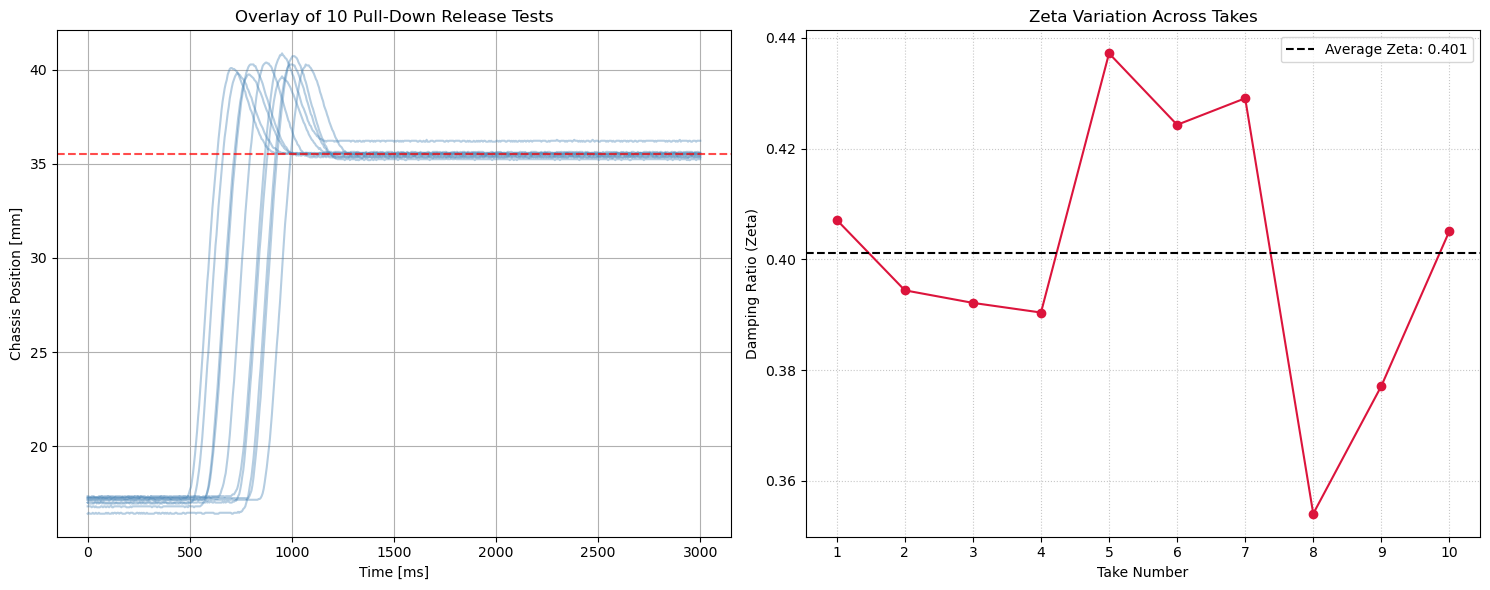

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# System parameters
m = 2.2977      # mass [kg]
k = 405.0       # spring stiffness [N/m]
c_c = 2 * np.sqrt(k * m)

num_tests = 10
zeta_list = []
c_list = []
valid_takes = []  # To track the x-axis numbers

# Makes the plot window with 2 subplots side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Printing the console table header
print(f"{'Test #':<8} | {'Zeta':<8} | {'Damping c (Ns/m)':<15} | {'Overshoot (%)':<15}")
print("-" * 55)

for i in range(1, num_tests + 1):
    file_path = f'{i}.csv'
    
    # Skips if a file is missing
    if not os.path.exists(file_path):
        continue
        
    df = pd.read_csv(file_path)
    t = df['Time_ms'].values
    y = df['Chassis_Position_mm'].values
    
    y_initial = np.mean(y[:50])
    y_final = np.mean(y[-50:])
    
    # Auto-detect direction
    if y_initial > y_final:
        peak_idx = np.argmin(y)
    else:
        peak_idx = np.argmax(y)
        
    y_max = y[peak_idx]
    
    step_size = abs(y_final - y_initial)
    overshoot = abs(y_max - y_final)
    overshoot_fraction = overshoot / step_size
    
    if 0 < overshoot_fraction < 1:
        zeta = -np.log(overshoot_fraction) / np.sqrt(np.pi**2 + np.log(overshoot_fraction)**2)
        c = zeta * c_c
        
        zeta_list.append(zeta)
        c_list.append(c)
        valid_takes.append(i)
        
        print(f"Take {i:<3} | {zeta:<8.4f} | {c:<15.4f} | {overshoot_fraction * 100:.1f}%")
    else:
        print(f"Take {i:<3} | {'INVALID':<8} | {'INVALID':<15} | {overshoot_fraction * 100:.1f}%")

    # Overlays all valid plots on the left hand graph
    ax1.plot(t, y, alpha=0.4, color='steelblue')

# Calculates averages and plots the second graph
if len(c_list) > 0:
    avg_zeta = np.mean(zeta_list)
    avg_c = np.mean(c_list)
    print("-" * 55)
    print(f"{'AVERAGE':<8} | {avg_zeta:<8.4f} | {avg_c:<15.4f} | -") 
    print(f"\nSuccessfully processed {len(c_list)} out of {num_tests} files.")
    
    # Plotting Zeta vs Take Number on the second graph (right)
    ax2.plot(valid_takes, zeta_list, marker='o', linestyle='-', color='crimson')
    ax2.axhline(avg_zeta, color='black', linestyle='--', label=f'Average Zeta: {avg_zeta:.3f}')
    ax2.set_xlabel('Take Number')
    ax2.set_ylabel('Damping Ratio (Zeta)')
    ax2.set_title('Zeta Variation Across Takes')
    ax2.set_xticks(valid_takes)
    ax2.grid(True, linestyle=':', alpha=0.7)
    ax2.legend()
else:
    print("\nNo valid data found to average.")

# Formatting the overlay plot (left)
ax1.axhline(y_final, color='red', linestyle='--', label='Average Steady State', alpha=0.7)
ax1.set_xlabel('Time [ms]')
ax1.set_ylabel('Chassis Position [mm]')
ax1.set_title(f'Overlay of {num_tests} Pull-Down Release Tests')
ax1.grid(True)

plt.tight_layout()
plt.show()

